In [1]:
import pandas as pd

In [2]:
train = pd.read_parquet("train-00000-of-00001.parquet")
validation = pd.read_parquet("validation-00000-of-00001.parquet")
test = pd.read_parquet("test-00000-of-00001.parquet")

In [3]:
print("Training:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Training: (7133, 14)
Validation: (1189, 14)
Test: (1189, 14)


In [4]:
print(train.columns.tolist())

['user1_id', 'user2_id', 'total_messages', 'aggressive_count', 'intent_to_harm', 'peerness', 'label', 'user1_age', 'user1_gender', 'user1_grade', 'user2_age', 'user2_gender', 'user2_grade', 'conversation']


In [5]:
train.head()

,user1_id,user2_id,total_messages,aggressive_count,intent_to_harm,peerness,label,user1_age,user1_gender,user1_grade,user2_age,user2_gender,user2_grade,conversation
0,31,88,11,3,0.273864,0.330000,0,18,Others,12,8,Female,2,"[{""message"": ""Not enough mention of the PS T..."
1,65,19,11,2,0.228409,NaN,0,15,Female,9,16,Others,10,"[{""message"": ""Famous People deleted from artic..."
2,17,55,17,8,0.447794,0.633333,1,8,Others,2,10,Others,4,"[{""message"": ""HOW DARE YOU EDIT MY SHIT AGAIN ..."
3,21,49,7,1,0.158929,0.366667,0,9,Others,3,15,Others,9,"[{""message"": ""BAD FAITH PART II I dont take ki..."
4,9,38,15,3,0.287500,0.233333,0,10,Female,4,18,Others,12,"[{""message"": ""That email is actually not suffi..."


In [6]:
train["label"].value_counts()

,count
label,
0,6389
1,744


In [7]:
train["label"].value_counts(normalize=True)

,proportion
label,
0,0.895696
1,0.104304


In [8]:
print(train.shape)
print(validation.shape)
print(test.shape)

print(train.columns.tolist())

train.head()

train["label"].value_counts()

(7133, 14)
(1189, 14)
(1189, 14)
['user1_id', 'user2_id', 'total_messages', 'aggressive_count', 'intent_to_harm', 'peerness', 'label', 'user1_age', 'user1_gender', 'user1_grade', 'user2_age', 'user2_gender', 'user2_grade', 'conversation']


,count
label,
0,6389
1,744


In [9]:
# Create sets containing each user pair
train_pairs = set(zip(train["user1_id"], train["user2_id"]))
validation_pairs = set(zip(validation["user1_id"], validation["user2_id"]))
test_pairs = set(zip(test["user1_id"], test["user2_id"]))

# Check overlap
print("Train ↔ Validation overlap:",
      len(train_pairs & validation_pairs))

print("Train ↔ Test overlap:",
      len(train_pairs & test_pairs))

print("Validation ↔ Test overlap:",
      len(validation_pairs & test_pairs))

Train ↔ Validation overlap: 0
Train ↔ Test overlap: 0
Validation ↔ Test overlap: 0


In [10]:
print(train["conversation"].iloc[0])
print(type(train["conversation"].iloc[0]))

[{"message": "Not enough mention of the PS   The PS had a profound impact on the BluRay format I think more information should be added regarding the PS and its role in BluRay", "label": 0}, {"message": "RT JabzzSalam Not sexist but girls on twitter arent funny", "label": 1}, {"message": "Important Note Charles is a vandal troll and malcontent you can check his history for yourselvesTim Foxworth", "label": 1}, {"message": "Your messages    I am sorry but what are you talking about", "label": 0}, {"message": "Vandalism only account     This account is up to no good and needs blocking", "label": 0}, {"message": "My personal experience does provide the context for my interpretation of reliable sources but I dont use it as a basis on which to add remove or modify information and I am able to commit to this", "label": 0}, {"message": "he drove of cliff lol haha lol this is well funny ahhhhhhhhhhhhhhhhh my ears are bleeding wow how old is she she is epic singer lol i was laughing for about  

In [11]:
import json

def extract_messages(conversation):
    messages = json.loads(conversation)
    return " ".join(item["message"] for item in messages)

In [12]:
train["text"] = train["conversation"].apply(extract_messages)
validation["text"] = validation["conversation"].apply(extract_messages)
test["text"] = test["conversation"].apply(extract_messages)

In [13]:
print(train.columns.tolist())

['user1_id', 'user2_id', 'total_messages', 'aggressive_count', 'intent_to_harm', 'peerness', 'label', 'user1_age', 'user1_gender', 'user1_grade', 'user2_age', 'user2_gender', 'user2_grade', 'conversation', 'text']


In [14]:
print(train[["text", "label"]].head())

                                                text  label
0  Not enough mention of the PS   The PS had a pr...      0
1  Famous People deleted from article by earlier ...      0
2  HOW DARE YOU EDIT MY SHIT AGAIN ARGGGGGHHHHHHH...      1
3  BAD FAITH PART II I dont take kindly to implie...      0
4  That email is actually not sufficient we cant ...      0


In [15]:
example = extract_messages(train["conversation"].iloc[0])

print(example[:1000])

Not enough mention of the PS   The PS had a profound impact on the BluRay format I think more information should be added regarding the PS and its role in BluRay RT JabzzSalam Not sexist but girls on twitter arent funny Important Note Charles is a vandal troll and malcontent you can check his history for yourselvesTim Foxworth Your messages    I am sorry but what are you talking about Vandalism only account     This account is up to no good and needs blocking My personal experience does provide the context for my interpretation of reliable sources but I dont use it as a basis on which to add remove or modify information and I am able to commit to this he drove of cliff lol haha lol this is well funny ahhhhhhhhhhhhhhhhh my ears are bleeding wow how old is she she is epic singer lol i was laughing for about  mins i found this so funny lol i dont think that is a chipmunk singing thats definatly justin beaber he laughed hes gay what is this song send email to ethanives ahhhhhhh puss in boo

In [16]:
print("Missing training text:", train["text"].isna().sum())
print("Missing validation text:", validation["text"].isna().sum())
print("Missing test text:", test["text"].isna().sum())

print("Empty training text:", (train["text"].str.strip() == "").sum())
print("Empty validation text:", (validation["text"].str.strip() == "").sum())
print("Empty test text:", (test["text"].str.strip() == "").sum())

Missing training text: 0
Missing validation text: 0
Missing test text: 0
Empty training text: 0
Empty validation text: 0
Empty test text: 0


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [18]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    lowercase=True
)

X_train_text = tfidf.fit_transform(train["text"])
X_val_text = tfidf.transform(validation["text"])

y_train = train["label"]
y_val = validation["label"]

In [19]:
model_text = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_text.fit(X_train_text, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [20]:
y_val_pred = model_text.predict(X_val_text)

In [21]:
print("Accuracy:", accuracy_score(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

Accuracy: 0.8410428931875525

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.86      0.91      1062
           1       0.37      0.69      0.48       127

    accuracy                           0.84      1189
   macro avg       0.66      0.78      0.69      1189
weighted avg       0.90      0.84      0.86      1189


Confusion Matrix:
[[912 150]
 [ 39  88]]


In [22]:
context_features = [
    "total_messages",
    "peerness",
    "user1_age",
    "user1_gender",
    "user1_grade",
    "user2_age",
    "user2_gender",
    "user2_grade"
]

print(train[context_features].isna().sum())

total_messages       0
peerness          3495
user1_age            0
user1_gender         0
user1_grade          0
user2_age            0
user2_gender         0
user2_grade          0
dtype: int64


In [23]:
print(train[context_features].dtypes)

total_messages      int64
peerness          float64
user1_age           int64
user1_gender       object
user1_grade         int64
user2_age           int64
user2_gender       object
user2_grade         int64
dtype: object


In [24]:
for column in context_features:
    print("\n", column)
    print(train[column].value_counts(dropna=False).head(10))


 total_messages
total_messages
2     550
6     521
3     511
5     501
4     490
1     487
7     470
8     408
9     388
10    353
Name: count, dtype: int64

 peerness
peerness
NaN         3495
0.700000     554
0.633333     505
0.566667     419
0.433333     337
0.766667     293
0.500000     226
0.300000     198
0.233333     181
0.366667     151
Name: count, dtype: int64

 user1_age
user1_age
8     889
11    850
15    836
16    712
13    706
10    679
9     648
17    505
18    498
14    432
Name: count, dtype: int64

 user1_gender
user1_gender
Others    3088
Female    2150
Male      1895
Name: count, dtype: int64

 user1_grade
user1_grade
2     889
5     850
9     836
10    712
7     706
4     679
3     648
11    505
12    498
8     432
Name: count, dtype: int64

 user2_age
user2_age
8     921
15    865
11    847
13    726
16    693
9     658
10    643
18    503
17    491
14    417
Name: count, dtype: int64

 user2_gender
user2_gender
Others    3153
Female    2117
Male      1863
Name: 

In [25]:
print(train["peerness"].describe())
print(train["peerness"].value_counts(dropna=False).head(10))

count    3638.000000
mean        0.536384
std         0.183950
min         0.100000
25%         0.433333
50%         0.566667
75%         0.700000
max         0.996667
Name: peerness, dtype: float64
peerness
NaN         3495
0.700000     554
0.633333     505
0.566667     419
0.433333     337
0.766667     293
0.500000     226
0.300000     198
0.233333     181
0.366667     151
Name: count, dtype: int64


In [26]:
numeric_features = [
    "total_messages",
    "peerness",
    "user1_age",
    "user1_grade",
    "user2_age",
    "user2_grade"
]

categorical_features = [
    "user1_gender",
    "user2_gender"
]

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

In [28]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [29]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [30]:
context_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [31]:
model_context = Pipeline(steps=[
    ("preprocessor", context_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

In [32]:
X_train_context = train[numeric_features + categorical_features]
X_val_context = validation[numeric_features + categorical_features]

y_train = train["label"]
y_val = validation["label"]

model_context.fit(X_train_context, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['total_messages', 'peerness',
                                                   'user1_age', 'user1_grade',
                                                   'user2_age',
                                                   'user2_grade']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['user1_gender',
                                                   'user2_gender'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [33]:
y_val_pred_context = model_context.predict(X_val_context)

In [34]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_context))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_context))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_context))

Accuracy: 0.8713204373423045

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.87      0.92      1062
           1       0.45      0.87      0.59       127

    accuracy                           0.87      1189
   macro avg       0.72      0.87      0.76      1189
weighted avg       0.93      0.87      0.89      1189


Confusion Matrix:
[[925 137]
 [ 16 111]]


In [35]:
combined_preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(
                max_features=10000,
                ngram_range=(1, 2),
                lowercase=True
            ),
            "text"
        ),

        (
            "num",
            numeric_transformer,
            numeric_features
        ),

        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [36]:
model_combined = Pipeline(steps=[
    ("preprocessor", combined_preprocessor),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

In [37]:
combined_features = (
    ["text"]
    + numeric_features
    + categorical_features
)

X_train_combined = train[combined_features]
X_val_combined = validation[combined_features]

y_train = train["label"]
y_val = validation["label"]

In [39]:
model_combined.fit(
    X_train_combined,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('text',
                                                  TfidfVectorizer(max_features=10000,
                                                                  ngram_range=(1,
                                                                               2)),
                                                  'text'),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['total_messages', 'peerness',
                                                   'user1_age', 'user1_grade',
                                                   'user2_age',
                                                   'user2_grade']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['user1_gender',
                                                   'user2_gender'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [40]:
y_val_pred_combined = model_combined.predict(
    X_val_combined
)

print(
    "Accuracy:",
    accuracy_score(y_val, y_val_pred_combined)
)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred_combined
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred_combined
    )
)

Accuracy: 0.8957106812447435

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.90      0.94      1062
           1       0.51      0.84      0.63       127

    accuracy                           0.90      1189
   macro avg       0.74      0.87      0.79      1189
weighted avg       0.93      0.90      0.91      1189


Confusion Matrix:
[[958 104]
 [ 20 107]]


In [41]:
from sklearn.svm import LinearSVC

In [42]:
svm_text = LinearSVC(
    class_weight="balanced",
    random_state=42
)

svm_text.fit(X_train_text, y_train)

y_val_pred_svm_text = svm_text.predict(X_val_text)

In [43]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_svm_text))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_svm_text))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_svm_text))

Accuracy: 0.8763666947014298

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      1062
           1       0.43      0.51      0.47       127

    accuracy                           0.88      1189
   macro avg       0.69      0.72      0.70      1189
weighted avg       0.89      0.88      0.88      1189


Confusion Matrix:
[[977  85]
 [ 62  65]]


In [44]:
svm_context = Pipeline(steps=[
    ("preprocessor", context_preprocessor),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

svm_context.fit(X_train_context, y_train)

y_val_pred_svm_context = svm_context.predict(X_val_context)

In [45]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_svm_context))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_svm_context))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_svm_context))

Accuracy: 0.8746846089150546

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.88      0.93      1062
           1       0.45      0.87      0.60       127

    accuracy                           0.87      1189
   macro avg       0.72      0.87      0.76      1189
weighted avg       0.93      0.87      0.89      1189


Confusion Matrix:
[[930 132]
 [ 17 110]]


In [46]:
svm_combined = Pipeline(steps=[
    ("preprocessor", combined_preprocessor),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

svm_combined.fit(X_train_combined, y_train)

y_val_pred_svm_combined = svm_combined.predict(X_val_combined)

In [47]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_svm_combined))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_svm_combined))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_svm_combined))

Accuracy: 0.9276703111858705

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      1062
           1       0.65      0.72      0.68       127

    accuracy                           0.93      1189
   macro avg       0.81      0.83      0.82      1189
weighted avg       0.93      0.93      0.93      1189


Confusion Matrix:
[[1012   50]
 [  36   91]]


In [48]:
from sklearn.ensemble import RandomForestClassifier

rf_context = Pipeline(steps=[
    ("preprocessor", context_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_context.fit(X_train_context, y_train)

y_val_pred_rf_context = rf_context.predict(X_val_context)

print("Accuracy:", accuracy_score(y_val, y_val_pred_rf_context))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf_context))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf_context))

Accuracy: 0.9411269974768713

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1062
           1       0.76      0.65      0.70       127

    accuracy                           0.94      1189
   macro avg       0.86      0.81      0.84      1189
weighted avg       0.94      0.94      0.94      1189


Confusion Matrix:
[[1036   26]
 [  44   83]]


In [49]:
rf_text = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_text.fit(X_train_text, y_train)

y_val_pred_rf_text = rf_text.predict(X_val_text)

print("Accuracy:", accuracy_score(y_val, y_val_pred_rf_text))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf_text))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf_text))

Accuracy: 0.8982338099243061

Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95      1062
           1       0.88      0.06      0.10       127

    accuracy                           0.90      1189
   macro avg       0.89      0.53      0.52      1189
weighted avg       0.90      0.90      0.86      1189


Confusion Matrix:
[[1061    1]
 [ 120    7]]


In [50]:
rf_combined = Pipeline(steps=[
    ("preprocessor", combined_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_combined.fit(X_train_combined, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('text',
                                                  TfidfVectorizer(max_features=10000,
                                                                  ngram_range=(1,
                                                                               2)),
                                                  'text'),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['total_messages', 'peerness',
                                                   'user1_age', 'user1_grade',
                                                   'user2_age',
                                                   'user2_grade']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['user1_gender',
                                                   'user2_gender'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

In [51]:
y_val_pred_rf_combined = rf_combined.predict(
    X_val_combined
)

print(
    "Accuracy:",
    accuracy_score(y_val, y_val_pred_rf_combined)
)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred_rf_combined
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred_rf_combined
    )
)

Accuracy: 0.9024390243902439

Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95      1062
           1       0.87      0.10      0.18       127

    accuracy                           0.90      1189
   macro avg       0.88      0.55      0.57      1189
weighted avg       0.90      0.90      0.87      1189


Confusion Matrix:
[[1060    2]
 [ 114   13]]


In [52]:
train_users = set(train["user1_id"]) | set(train["user2_id"])
val_users = set(validation["user1_id"]) | set(validation["user2_id"])
test_users = set(test["user1_id"]) | set(test["user2_id"])

print("Unique train users:", len(train_users))
print("Unique validation users:", len(val_users))
print("Unique test users:", len(test_users))

print("\nTrain ↔ Validation user overlap:",
      len(train_users & val_users))

print("Train ↔ Test user overlap:",
      len(train_users & test_users))

print("Validation ↔ Test user overlap:",
      len(val_users & test_users))

Unique train users: 100
Unique validation users: 100
Unique test users: 100

Train ↔ Validation user overlap: 100
Train ↔ Test user overlap: 100
Validation ↔ Test user overlap: 100


In [53]:
X_test_text = tfidf.transform(test["text"])

X_test_context = test[numeric_features + categorical_features]

X_test_combined = test[combined_features]

y_test = test["label"]

In [54]:
y_test_pred_svm_text = svm_text.predict(X_test_text)

print("=== SVM TEXT ===")
print("Accuracy:", accuracy_score(y_test, y_test_pred_svm_text))
print(classification_report(y_test, y_test_pred_svm_text))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_svm_text))


=== SVM TEXT ===
Accuracy: 0.8570227081581161
              precision    recall  f1-score   support

           0       0.95      0.89      0.92      1068
           1       0.37      0.56      0.44       121

    accuracy                           0.86      1189
   macro avg       0.66      0.73      0.68      1189
weighted avg       0.89      0.86      0.87      1189

Confusion Matrix:
[[951 117]
 [ 53  68]]


In [55]:
y_test_pred_svm_context = svm_context.predict(X_test_context)

print("=== SVM CONTEXT ===")
print("Accuracy:", accuracy_score(y_test, y_test_pred_svm_context))
print(classification_report(y_test, y_test_pred_svm_context))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_svm_context))

=== SVM CONTEXT ===
Accuracy: 0.8544995794785534
              precision    recall  f1-score   support

           0       0.99      0.85      0.91      1068
           1       0.40      0.90      0.56       121

    accuracy                           0.85      1189
   macro avg       0.70      0.88      0.74      1189
weighted avg       0.93      0.85      0.88      1189

Confusion Matrix:
[[907 161]
 [ 12 109]]


In [56]:
y_test_pred_svm_combined = svm_combined.predict(X_test_combined)

print("=== SVM COMBINED ===")
print("Accuracy:", accuracy_score(y_test, y_test_pred_svm_combined))
print(classification_report(y_test, y_test_pred_svm_combined))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_svm_combined))

=== SVM COMBINED ===
Accuracy: 0.9192598822539949
              precision    recall  f1-score   support

           0       0.97      0.94      0.95      1068
           1       0.58      0.78      0.66       121

    accuracy                           0.92      1189
   macro avg       0.78      0.86      0.81      1189
weighted avg       0.93      0.92      0.92      1189

Confusion Matrix:
[[999  69]
 [ 27  94]]


In [57]:
y_test_pred_lr_text = model_text.predict(X_test_text)

print("=== LOGISTIC REGRESSION — TEXT ===")
print("Accuracy:", accuracy_score(y_test, y_test_pred_lr_text))
print(classification_report(y_test, y_test_pred_lr_text))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_lr_text))

=== LOGISTIC REGRESSION — TEXT ===
Accuracy: 0.8259041211101766
              precision    recall  f1-score   support

           0       0.97      0.83      0.90      1068
           1       0.34      0.77      0.47       121

    accuracy                           0.83      1189
   macro avg       0.66      0.80      0.68      1189
weighted avg       0.91      0.83      0.85      1189

Confusion Matrix:
[[889 179]
 [ 28  93]]


In [58]:
y_test_pred_lr_context = model_context.predict(X_test_context)

print("=== LOGISTIC REGRESSION — CONTEXT ===")
print("Accuracy:", accuracy_score(y_test, y_test_pred_lr_context))
print(classification_report(y_test, y_test_pred_lr_context))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_lr_context))

=== LOGISTIC REGRESSION — CONTEXT ===
Accuracy: 0.8536585365853658
              precision    recall  f1-score   support

           0       0.99      0.85      0.91      1068
           1       0.40      0.91      0.56       121

    accuracy                           0.85      1189
   macro avg       0.70      0.88      0.74      1189
weighted avg       0.93      0.85      0.88      1189

Confusion Matrix:
[[905 163]
 [ 11 110]]


In [59]:
y_test_pred_lr_combined = model_combined.predict(X_test_combined)

print("=== LOGISTIC REGRESSION — COMBINED ===")
print("Accuracy:", accuracy_score(y_test, y_test_pred_lr_combined))
print(classification_report(y_test, y_test_pred_lr_combined))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_lr_combined))

=== LOGISTIC REGRESSION — COMBINED ===
Accuracy: 0.8805719091673675
              precision    recall  f1-score   support

           0       0.98      0.88      0.93      1068
           1       0.45      0.84      0.59       121

    accuracy                           0.88      1189
   macro avg       0.72      0.86      0.76      1189
weighted avg       0.93      0.88      0.90      1189

Confusion Matrix:
[[945 123]
 [ 19 102]]


In [60]:
y_test_pred_rf_text = rf_text.predict(X_test_text)

print("=== RANDOM FOREST — TEXT ===")
print("Accuracy:", accuracy_score(y_test, y_test_pred_rf_text))
print(classification_report(y_test, y_test_pred_rf_text))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf_text))

=== RANDOM FOREST — TEXT ===
Accuracy: 0.896551724137931
              precision    recall  f1-score   support

           0       0.90      0.99      0.95      1068
           1       0.42      0.04      0.08       121

    accuracy                           0.90      1189
   macro avg       0.66      0.52      0.51      1189
weighted avg       0.85      0.90      0.86      1189

Confusion Matrix:
[[1061    7]
 [ 116    5]]


In [61]:
y_test_pred_rf_context = rf_context.predict(X_test_context)

print("=== RANDOM FOREST — CONTEXT ===")
print("Accuracy:", accuracy_score(y_test, y_test_pred_rf_context))
print(classification_report(y_test, y_test_pred_rf_context))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf_context))

=== RANDOM FOREST — CONTEXT ===
Accuracy: 0.9428090832632464
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1068
           1       0.76      0.64      0.70       121

    accuracy                           0.94      1189
   macro avg       0.86      0.81      0.83      1189
weighted avg       0.94      0.94      0.94      1189

Confusion Matrix:
[[1043   25]
 [  43   78]]


In [62]:
y_test_pred_rf_combined = rf_combined.predict(X_test_combined)

print("=== RANDOM FOREST — COMBINED ===")
print("Accuracy:", accuracy_score(y_test, y_test_pred_rf_combined))
print(classification_report(y_test, y_test_pred_rf_combined))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf_combined))

=== RANDOM FOREST — COMBINED ===
Accuracy: 0.8990748528174937
              precision    recall  f1-score   support

           0       0.90      1.00      0.95      1068
           1       0.55      0.05      0.09       121

    accuracy                           0.90      1189
   macro avg       0.72      0.52      0.52      1189
weighted avg       0.87      0.90      0.86      1189

Confusion Matrix:
[[1063    5]
 [ 115    6]]


In [63]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import pandas as pd

results = []

def add_result(name, features, y_true, y_pred):
    results.append({
        "Classifier": name,
        "Features": features,
        "Accuracy": accuracy_score(y_true, y_pred),
        "CB Precision": precision_score(y_true, y_pred, pos_label=1),
        "CB Recall": recall_score(y_true, y_pred, pos_label=1),
        "CB F1": f1_score(y_true, y_pred, pos_label=1)
    })

# Logistic Regression
add_result("Logistic Regression", "Text",
           y_test, y_test_pred_lr_text)

add_result("Logistic Regression", "Context",
           y_test, y_test_pred_lr_context)

add_result("Logistic Regression", "Combined",
           y_test, y_test_pred_lr_combined)

# Linear SVM
add_result("Linear SVM", "Text",
           y_test, y_test_pred_svm_text)

add_result("Linear SVM", "Context",
           y_test, y_test_pred_svm_context)

add_result("Linear SVM", "Combined",
           y_test, y_test_pred_svm_combined)

# Random Forest
add_result("Random Forest", "Text",
           y_test, y_test_pred_rf_text)

add_result("Random Forest", "Context",
           y_test, y_test_pred_rf_context)

add_result("Random Forest", "Combined",
           y_test, y_test_pred_rf_combined)

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

         Classifier Features  Accuracy  CB Precision  CB Recall  CB F1
Logistic Regression     Text     0.826         0.342      0.769  0.473
Logistic Regression  Context     0.854         0.403      0.909  0.558
Logistic Regression Combined     0.881         0.453      0.843  0.590
         Linear SVM     Text     0.857         0.368      0.562  0.444
         Linear SVM  Context     0.854         0.404      0.901  0.558
         Linear SVM Combined     0.919         0.577      0.777  0.662
      Random Forest     Text     0.897         0.417      0.041  0.075
      Random Forest  Context     0.943         0.757      0.645  0.696
      Random Forest Combined     0.899         0.545      0.050  0.091


In [64]:
comparison = pd.DataFrame({
    "actual": y_test.values,
    "text_prediction": y_test_pred_svm_text,
    "combined_prediction": y_test_pred_svm_combined
})

comparison.head()

,actual,text_prediction,combined_prediction
0,0,1,1
1,0,0,0
2,0,0,0
3,0,1,1
4,0,0,0


In [65]:
comparison["text_correct"] = (
    comparison["actual"] == comparison["text_prediction"]
)

comparison["combined_correct"] = (
    comparison["actual"] == comparison["combined_prediction"]
)

In [66]:
print(pd.crosstab(
    comparison["text_correct"],
    comparison["combined_correct"]
))

combined_correct  False  True 
text_correct                  
False                69    101
True                 27    992


In [67]:
from statsmodels.stats.contingency_tables import mcnemar

In [68]:
mcnemar_table = [
    [992, 27],
    [101, 69]
]

In [69]:
result = mcnemar(
    mcnemar_table,
    exact=True
)

print("McNemar statistic:", result.statistic)
print("p-value:", result.pvalue)

McNemar statistic: 27.0
p-value: 2.9860859870559856e-11


In [70]:
import numpy as np
from sklearn.metrics import f1_score

rng = np.random.default_rng(42)

y_true = np.asarray(y_test)
pred_text = np.asarray(y_test_pred_svm_text)
pred_combined = np.asarray(y_test_pred_svm_combined)

n_bootstrap = 5000
f1_differences = []

n = len(y_true)

for _ in range(n_bootstrap):

    # Sample test-set indices with replacement
    indices = rng.choice(n, size=n, replace=True)

    y_sample = y_true[indices]
    text_sample = pred_text[indices]
    combined_sample = pred_combined[indices]

    # Calculate cyberbullying F1
    text_f1 = f1_score(
        y_sample,
        text_sample,
        pos_label=1
    )

    combined_f1 = f1_score(
        y_sample,
        combined_sample,
        pos_label=1
    )

    f1_differences.append(
        combined_f1 - text_f1
    )

f1_differences = np.array(f1_differences)

lower = np.percentile(f1_differences, 2.5)
upper = np.percentile(f1_differences, 97.5)
mean_difference = np.mean(f1_differences)

print("Mean F1 difference:", mean_difference)
print("95% bootstrap CI:", (lower, upper))

Mean F1 difference: 0.21752581561877904
95% bootstrap CI: (np.float64(0.15260237030728835), np.float64(0.2838718284237998))


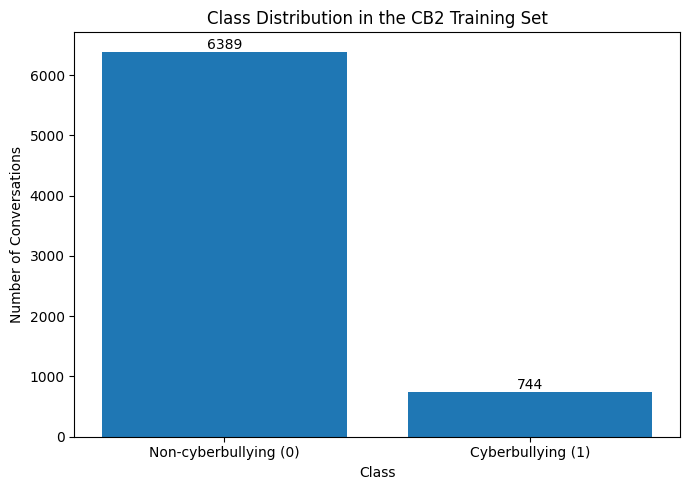

In [71]:
import matplotlib.pyplot as plt

# Count classes in the training set
class_counts = train["label"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Non-cyberbullying (0)", "Cyberbullying (1)"],
    class_counts.values
)

plt.title("Class Distribution in the CB2 Training Set")
plt.xlabel("Class")
plt.ylabel("Number of Conversations")

# Add exact counts above bars
for bar, count in zip(bars, class_counts.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [72]:
class_percentages = (
    train["label"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(class_percentages.round(2))

Class counts:
label
0    6389
1     744
Name: count, dtype: int64

Class percentages:
label
0    89.57
1    10.43
Name: proportion, dtype: float64


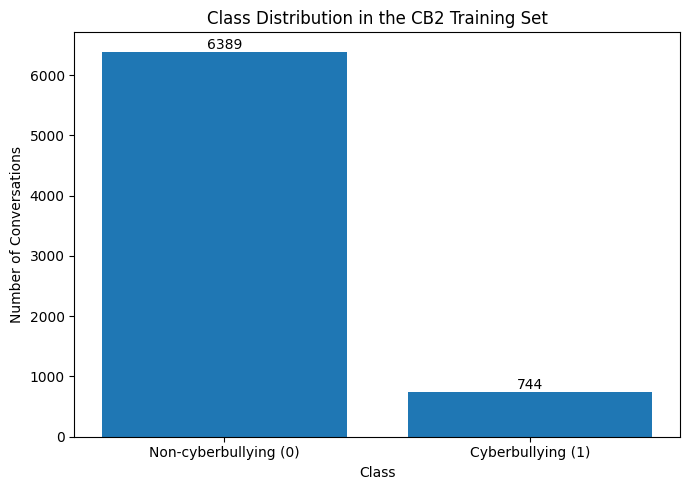

In [73]:
plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Non-cyberbullying (0)", "Cyberbullying (1)"],
    class_counts.values
)

plt.title("Class Distribution in the CB2 Training Set")
plt.xlabel("Class")
plt.ylabel("Number of Conversations")

for bar, count in zip(bars, class_counts.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "figure_1_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plot_data = pd.DataFrame({
    "Classifier": [
        "Logistic Regression",
        "Linear SVM",
        "Random Forest"
    ],
    "Text": [
        0.473,
        0.444,
        0.075
    ],
    "Context": [
        0.558,
        0.558,
        0.696
    ],
    "Combined": [
        0.590,
        0.662,
        0.091
    ]
})

plot_data

,Classifier,Text,Context,Combined
0,Logistic Regression,0.473,0.558,0.590
1,Linear SVM,0.444,0.558,0.662
2,Random Forest,0.075,0.696,0.091


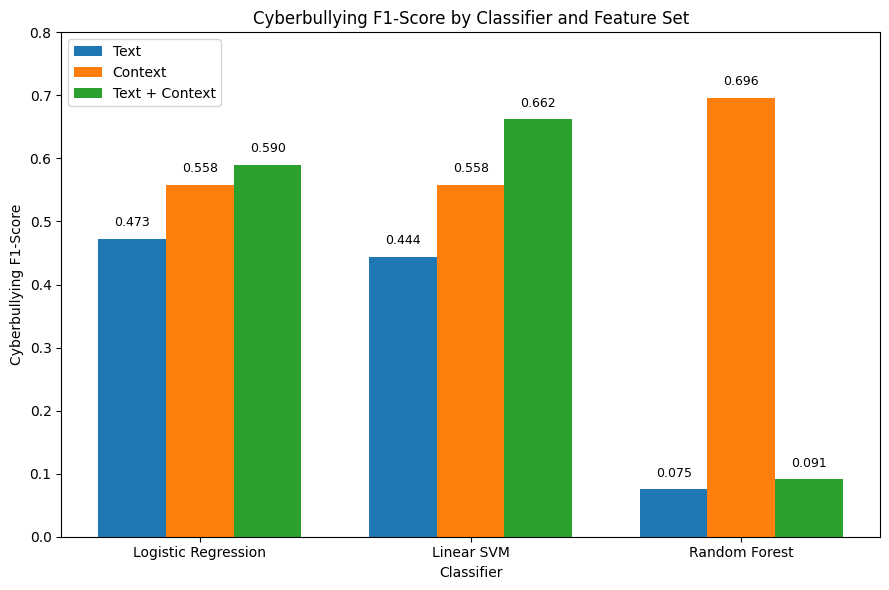

In [75]:
x = np.arange(len(plot_data["Classifier"]))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 6))

bars1 = ax.bar(
    x - width,
    plot_data["Text"],
    width,
    label="Text"
)

bars2 = ax.bar(
    x,
    plot_data["Context"],
    width,
    label="Context"
)

bars3 = ax.bar(
    x + width,
    plot_data["Combined"],
    width,
    label="Text + Context"
)

ax.set_title(
    "Cyberbullying F1-Score by Classifier and Feature Set"
)

ax.set_xlabel("Classifier")
ax.set_ylabel("Cyberbullying F1-Score")

ax.set_xticks(x)
ax.set_xticklabels(plot_data["Classifier"])

ax.set_ylim(0, 0.8)

ax.legend()

# Put exact F1 values above bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.015,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()

plt.savefig(
    "figure_2_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

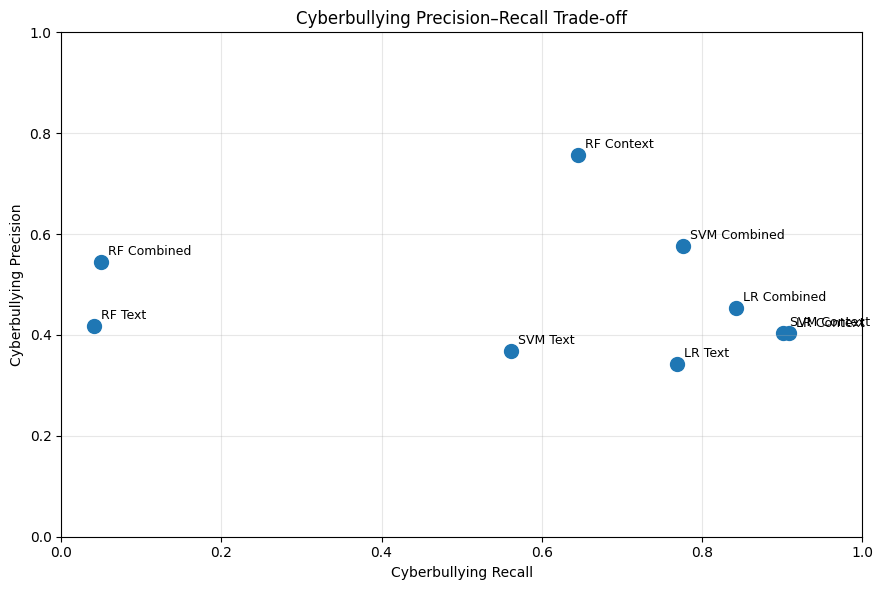

In [76]:
import matplotlib.pyplot as plt
import pandas as pd

pr_data = pd.DataFrame({
    "Model": [
        "LR Text",
        "LR Context",
        "LR Combined",
        "SVM Text",
        "SVM Context",
        "SVM Combined",
        "RF Text",
        "RF Context",
        "RF Combined"
    ],
    "Precision": [
        0.342,
        0.403,
        0.453,
        0.368,
        0.404,
        0.577,
        0.417,
        0.757,
        0.545
    ],
    "Recall": [
        0.769,
        0.909,
        0.843,
        0.562,
        0.901,
        0.777,
        0.041,
        0.645,
        0.050
    ]
})

plt.figure(figsize=(9, 6))

plt.scatter(
    pr_data["Recall"],
    pr_data["Precision"],
    s=100
)

for _, row in pr_data.iterrows():
    plt.annotate(
        row["Model"],
        (row["Recall"], row["Precision"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.title("Cyberbullying Precision–Recall Trade-off")
plt.xlabel("Cyberbullying Recall")
plt.ylabel("Cyberbullying Precision")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figure_3_precision_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

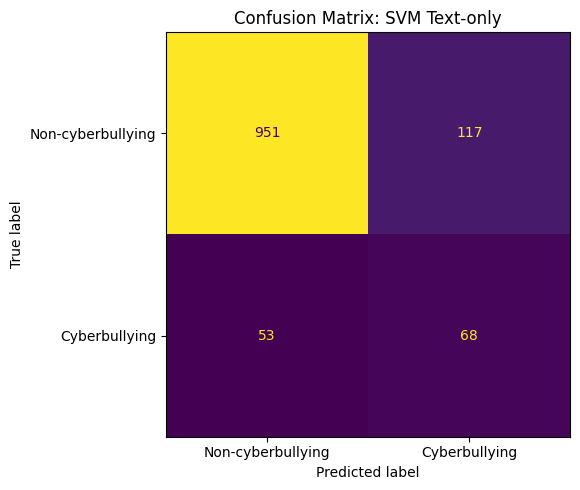

In [77]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm_text = confusion_matrix(
    y_test,
    y_test_pred_svm_text
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_text,
    display_labels=[
        "Non-cyberbullying",
        "Cyberbullying"
    ]
)

fig, ax = plt.subplots(figsize=(6, 5))

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Confusion Matrix: SVM Text-only"
)

plt.tight_layout()

plt.savefig(
    "figure_4a_svm_text_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

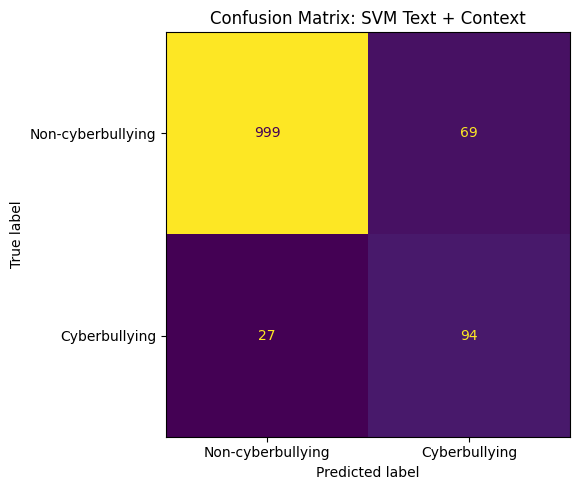

In [78]:
cm_combined = confusion_matrix(
    y_test,
    y_test_pred_svm_combined
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_combined,
    display_labels=[
        "Non-cyberbullying",
        "Cyberbullying"
    ]
)

fig, ax = plt.subplots(figsize=(6, 5))

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Confusion Matrix: SVM Text + Context"
)

plt.tight_layout()

plt.savefig(
    "figure_4b_svm_combined_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

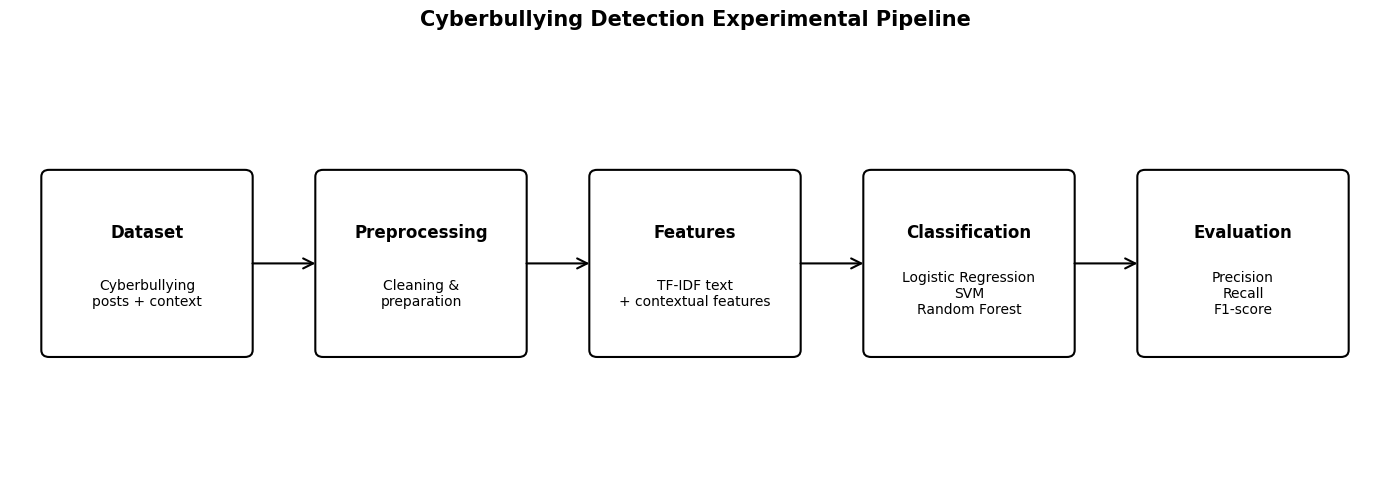

In [79]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(14, 5))
ax.set_xlim(0, 14)
ax.set_ylim(0, 5)
ax.axis("off")

steps = [
    ("Dataset", "Cyberbullying\nposts + context"),
    ("Preprocessing", "Cleaning &\npreparation"),
    ("Features", "TF-IDF text\n+ contextual features"),
    ("Classification", "Logistic Regression\nSVM\nRandom Forest"),
    ("Evaluation", "Precision\nRecall\nF1-score"),
]

x_positions = [0.4, 3.2, 6.0, 8.8, 11.6]

for i, (title, detail) in enumerate(steps):
    x = x_positions[i]

    box = FancyBboxPatch(
        (x, 1.5),
        2.0,
        2.0,
        boxstyle="round,pad=0.08",
        linewidth=1.5,
        facecolor="white",
        edgecolor="black"
    )

    ax.add_patch(box)

    ax.text(
        x + 1.0, 2.85,
        title,
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

    ax.text(
        x + 1.0, 2.15,
        detail,
        ha="center",
        va="center",
        fontsize=10
    )

    if i < len(steps) - 1:
        arrow = FancyArrowPatch(
            (x + 2.05, 2.5),
            (x_positions[i + 1] - 0.05, 2.5),
            arrowstyle="->",
            mutation_scale=18,
            linewidth=1.5
        )
        ax.add_patch(arrow)

ax.set_title(
    "Cyberbullying Detection Experimental Pipeline",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.tight_layout()

plt.savefig(
    "figure_5_methodology_pipeline.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [80]:
import pandas as pd

stats_table = pd.DataFrame({
    "Measure": [
        "SVM Text-only cyberbullying F1",
        "SVM Combined cyberbullying F1",
        "Absolute F1 improvement",
        "Mean bootstrap F1 difference",
        "95% bootstrap CI",
        "Text wrong → Combined correct",
        "Text correct → Combined wrong",
        "Exact McNemar p-value"
    ],
    "Result": [
        "0.444",
        "0.662",
        "0.218",
        "0.218",
        "[0.153, 0.284]",
        "101",
        "27",
        "2.99 × 10⁻¹¹"
    ]
})

stats_table

,Measure,Result
0,SVM Text-only cyberbullying F1,0.444
1,SVM Combined cyberbullying F1,0.662
2,Absolute F1 improvement,0.218
3,Mean bootstrap F1 difference,0.218
4,95% bootstrap CI,"[0.153, 0.284]"
5,Text wrong → Combined correct,101
6,Text correct → Combined wrong,27
7,Exact McNemar p-value,2.99 × 10⁻¹¹


In [81]:
stats_table.to_csv(
    "table_statistical_comparison.csv",
    index=False
)

In [85]:
import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(name, "->", obj.shape)

train -> (7133, 15)
validation -> (1189, 15)
test -> (1189, 15)
_5 -> (5, 14)
X_train_context -> (7133, 8)
X_val_context -> (1189, 8)
X_train_combined -> (7133, 9)
X_val_combined -> (1189, 9)
X_test_context -> (1189, 8)
X_test_combined -> (1189, 9)
results_df -> (9, 6)
comparison -> (1189, 5)
_64 -> (5, 3)
plot_data -> (3, 4)
_74 -> (3, 4)
pr_data -> (9, 3)
stats_table -> (8, 2)
_80 -> (8, 2)


In [87]:
print("Dataset shape:", train.shape)
print("\nColumns:")
print(train.columns.tolist())

print("\nTarget distribution:")
print(train["label"].value_counts())

print("\nTarget percentages:")
print(
    train["label"]
      .value_counts(normalize=True)
      .mul(100)
      .round(2)
)

Dataset shape: (7133, 15)

Columns:
['user1_id', 'user2_id', 'total_messages', 'aggressive_count', 'intent_to_harm', 'peerness', 'label', 'user1_age', 'user1_gender', 'user1_grade', 'user2_age', 'user2_gender', 'user2_grade', 'conversation', 'text']

Target distribution:
label
0    6389
1     744
Name: count, dtype: int64

Target percentages:
label
0    89.57
1    10.43
Name: proportion, dtype: float64


In [88]:
import pandas as pd

dataframes = []

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        dataframes.append((name, obj.shape))

print("DataFrames currently in memory:")
for name, shape in dataframes:
    print(f"{name} -> {shape}")

if not dataframes:
    print("NONE FOUND")

DataFrames currently in memory:
train -> (7133, 15)
validation -> (1189, 15)
test -> (1189, 15)
_5 -> (5, 14)
X_train_context -> (7133, 8)
X_val_context -> (1189, 8)
X_train_combined -> (7133, 9)
X_val_combined -> (1189, 9)
X_test_context -> (1189, 8)
X_test_combined -> (1189, 9)
results_df -> (9, 6)
comparison -> (1189, 5)
_64 -> (5, 3)
plot_data -> (3, 4)
_74 -> (3, 4)
pr_data -> (9, 3)
stats_table -> (8, 2)
_80 -> (8, 2)


In [89]:
import pandas as pd
import json

train = pd.read_parquet("train-00000-of-00001.parquet")
validation = pd.read_parquet("validation-00000-of-00001.parquet")
test = pd.read_parquet("test-00000-of-00001.parquet")

def extract_messages(conversation):
    messages = json.loads(conversation)
    return " ".join(item["message"] for item in messages)

train["text"] = train["conversation"].apply(extract_messages)
validation["text"] = validation["conversation"].apply(extract_messages)
test["text"] = test["conversation"].apply(extract_messages)

In [90]:
import pandas as pd
import json

train = pd.read_parquet("train-00000-of-00001.parquet")
validation = pd.read_parquet("validation-00000-of-00001.parquet")
test = pd.read_parquet("test-00000-of-00001.parquet")

def extract_messages(conversation):
    messages = json.loads(conversation)
    return " ".join(item["message"] for item in messages)

train["text"] = train["conversation"].apply(extract_messages)
validation["text"] = validation["conversation"].apply(extract_messages)
test["text"] = test["conversation"].apply(extract_messages)

In [91]:
print("Training shape:", train.shape)
print("Validation shape:", validation.shape)
print("Test shape:", test.shape)

print("\nTraining label counts:")
print(train["label"].value_counts().sort_index())

print("\nTraining label percentages:")
print(
    train["label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nColumns:")
print(train.columns.tolist())

Training shape: (7133, 15)
Validation shape: (1189, 15)
Test shape: (1189, 15)

Training label counts:
label
0    6389
1     744
Name: count, dtype: int64

Training label percentages:
label
0    89.57
1    10.43
Name: proportion, dtype: float64

Columns:
['user1_id', 'user2_id', 'total_messages', 'aggressive_count', 'intent_to_harm', 'peerness', 'label', 'user1_age', 'user1_gender', 'user1_grade', 'user2_age', 'user2_gender', 'user2_grade', 'conversation', 'text']
